In [4]:
from sklearn.datasets import fetch_openml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


freq = fetch_openml(data_id=41214, as_frame=True).frame   # Frequenz-Daten
sev  = fetch_openml(data_id=41215, as_frame=True).frame   # Schadenhöhen


Übersicht von Datensatz beschaffen:

In [5]:

freq.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [6]:
freq.info()

<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678013 non-null  float64 
 1   ClaimNb     678013 non-null  int64   
 2   Exposure    678013 non-null  float64 
 3   Area        678013 non-null  category
 4   VehPower    678013 non-null  int64   
 5   VehAge      678013 non-null  int64   
 6   DrivAge     678013 non-null  int64   
 7   BonusMalus  678013 non-null  int64   
 8   VehBrand    678013 non-null  category
 9   VehGas      678013 non-null  str     
 10  Density     678013 non-null  int64   
 11  Region      678013 non-null  category
dtypes: category(3), float64(2), int64(6), str(1)
memory usage: 48.5 MB


In [7]:
freq.describe()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405
std,1.641783e+06,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,6.114330e+06,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000


In [8]:
freq.isna().sum()

IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
dtype: int64

Datenqualität prüfen:

In [9]:

# Exposure: Versicherungsdauer in Jahren, sollte maximal 1 sein
print("Exposure > 1:", (freq["Exposure"] > 1).sum())
print("Exposure max:", freq["Exposure"].max())

# Schadenanzahl
print(freq["ClaimNb"].value_counts().sort_index())

Exposure > 1: 1224
Exposure max: 2.01
ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64


In [10]:
# Schadenhöhen
sev["ClaimAmount"].describe()

count    2.663900e+04
mean     2.278536e+03
std      2.929748e+04
min      1.000000e+00
25%      6.868100e+02
50%      1.172000e+03
75%      1.228080e+03
max      4.075401e+06
Name: ClaimAmount, dtype: float64

In [11]:
# Die grössten Einzelschäden
sev.sort_values("ClaimAmount", ascending=False).head(10)

,IDpol,ClaimAmount
9756,1120377,4075400.56
15768,110846,1403057.40
11637,2141337,1301172.60
17992,3122016,774411.50
2869,2008127,390742.27
3307,3025890,369131.88
9999,1117644,307096.42
5521,158309,301635.49
18627,3075820,287423.00
18295,3150210,281897.49


Kennzahlen zur Frquenz:

In [12]:
total_claims = freq["ClaimNb"].sum()
total_exposure = freq["Exposure"].sum()

print(f"Policen:          {len(freq):,}")
print(f"Schäden gesamt:   {total_claims:,}")
print(f"Exposure (Jahre): {total_exposure:,.0f}")
print(f"Gesamtfrequenz:   {total_claims / total_exposure:.4f}")

Policen:          678,013
Schäden gesamt:   36,102
Exposure (Jahre): 358,499
Gesamtfrequenz:   0.1007


Verteilungen ploten:

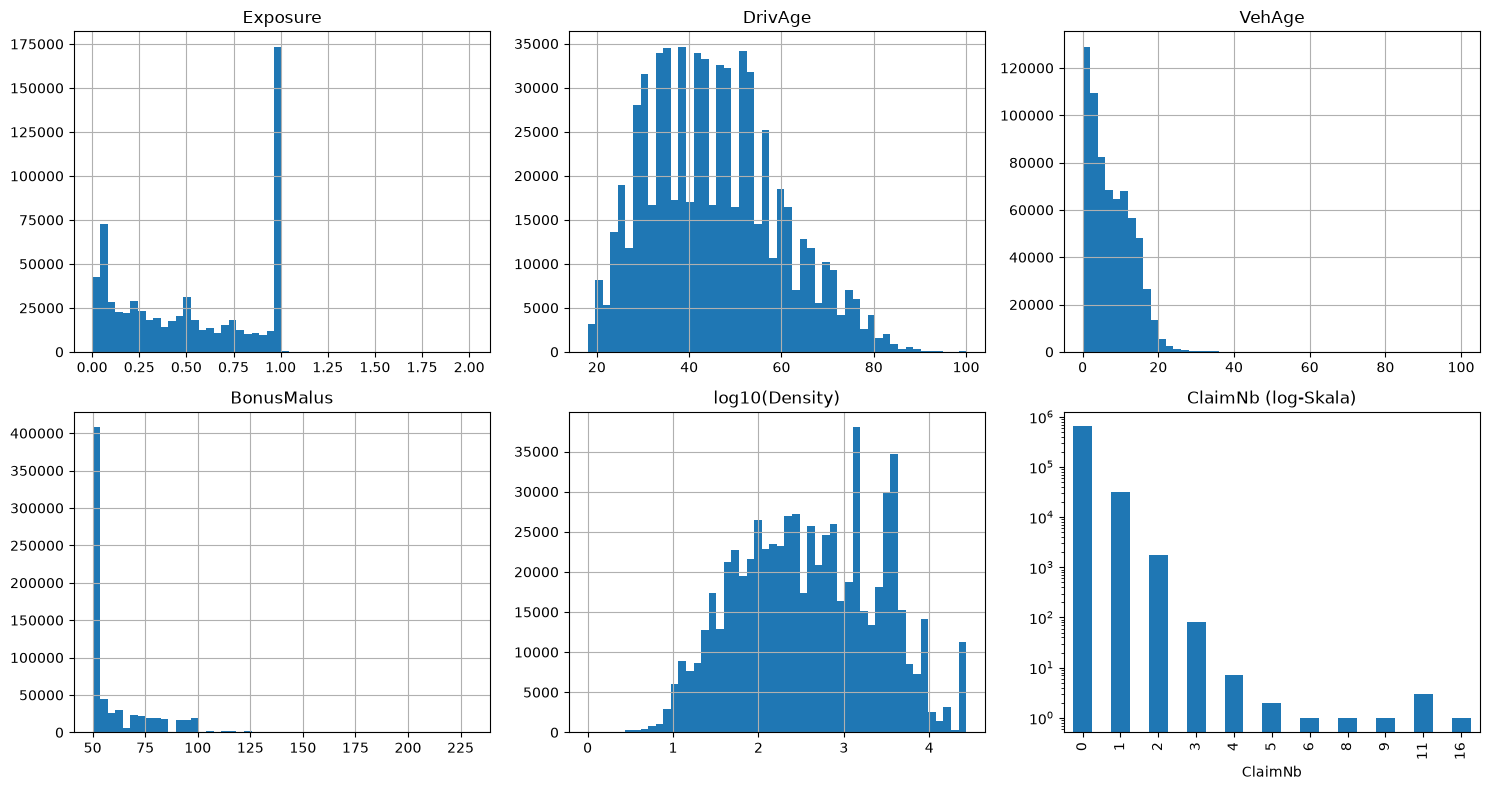

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

freq["Exposure"].hist(bins=50, ax=axes[0, 0]); axes[0, 0].set_title("Exposure")
freq["DrivAge"].hist(bins=50, ax=axes[0, 1]);  axes[0, 1].set_title("DrivAge")
freq["VehAge"].hist(bins=50, ax=axes[0, 2]);   axes[0, 2].set_title("VehAge")
freq["BonusMalus"].hist(bins=50, ax=axes[1, 0]); axes[1, 0].set_title("BonusMalus")
np.log10(freq["Density"]).hist(bins=50, ax=axes[1, 1]); axes[1, 1].set_title("log10(Density)")
freq["ClaimNb"].value_counts().sort_index().plot.bar(ax=axes[1, 2], logy=True)
axes[1, 2].set_title("ClaimNb (log-Skala)")

plt.tight_layout()
plt.savefig("../results/01_distributions.png", dpi=150)
plt.show()

Frequenz nach Merkmalen:

In [14]:
def freq_by(df, col, bins=None):
    """Schadenfrequenz und Exposure pro Gruppe einer Variable."""
    g = df[col]
    if bins is not None:
        g = pd.cut(g, bins=bins)
    out = (df.groupby(g, observed=True)
             .agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum")))
    out["frequency"] = out["claims"] / out["exposure"]
    return out

freq_by(freq, "VehBrand")

,claims,exposure,frequency
VehBrand,,,
B1,8677,95351.059578,0.091001
B10,858,9496.014123,0.090354
B11,721,6887.817279,0.104678
B12,8859,64808.608718,0.136695
B13,649,6772.032216,0.095835
B14,166,2274.467743,0.072984
B2,8560,94864.057101,0.090234
B3,2818,28592.876331,0.098556
B4,1312,13775.496080,0.095242


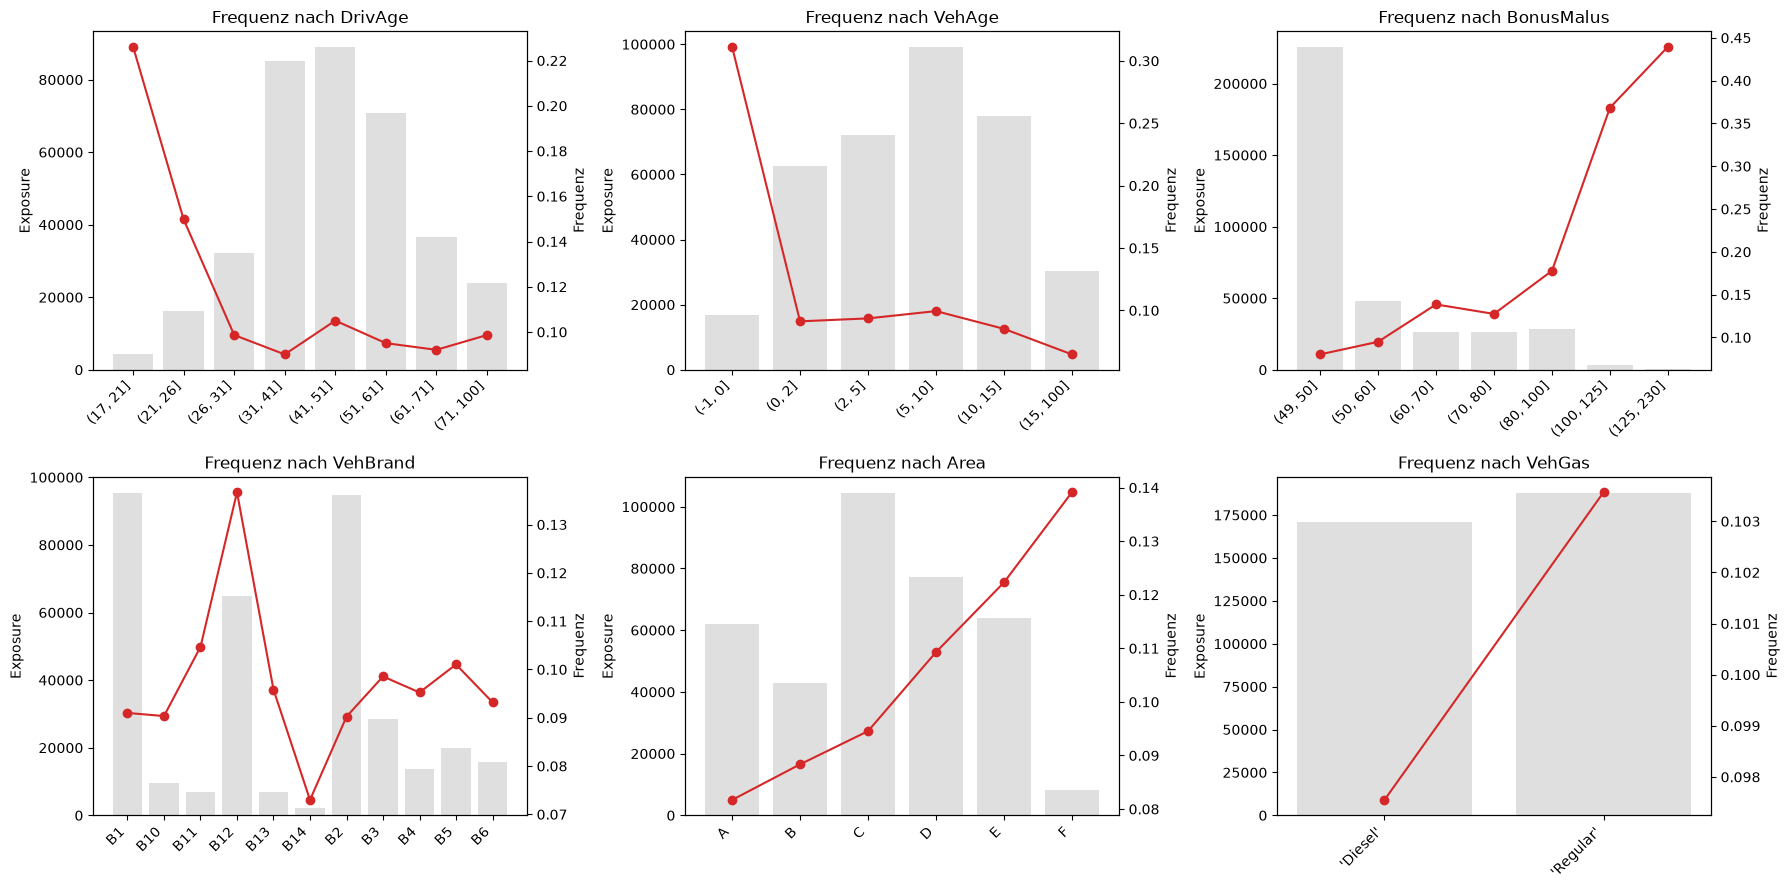

In [15]:
def plot_freq(df, col, bins=None, ax=None):
    t = freq_by(df, col, bins)
    ax = ax or plt.gca()
    ax.bar(range(len(t)), t["exposure"], alpha=0.25, color="grey")   # Volumen
    ax.set_ylabel("Exposure")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right")
    ax2 = ax.twinx()
    ax2.plot(range(len(t)), t["frequency"], marker="o", color="C3")
    ax2.set_ylabel("Frequenz")
    ax.set_title(f"Frequenz nach {col}")

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
plot_freq(freq, "DrivAge", bins=[17, 21, 26, 31, 41, 51, 61, 71, 100], ax=axes[0, 0])
plot_freq(freq, "VehAge", bins=[-1, 0, 2, 5, 10, 15, 100], ax=axes[0, 1])
plot_freq(freq, "BonusMalus", bins=[49, 50, 60, 70, 80, 100, 125, 230], ax=axes[0, 2])
plot_freq(freq, "VehBrand", ax=axes[1, 0])
plot_freq(freq, "Area", ax=axes[1, 1])
plot_freq(freq, "VehGas", ax=axes[1, 2])

plt.tight_layout()
plt.savefig("../results/02_frequency_by_feature.png", dpi=150)
plt.show()

Die grauen Balken zeigen, wie viel Daten in jeder Gruppe stecken. Die rote Linie ist die Frequenz. Ist ein Balken sehr klein, ist die Frequenz dort unsicher. Typische Muster: junge Fahrer haben hohe Frequenz, BonusMalus steigt klar mit dem Risiko.

Schadenhöhe ansehen:

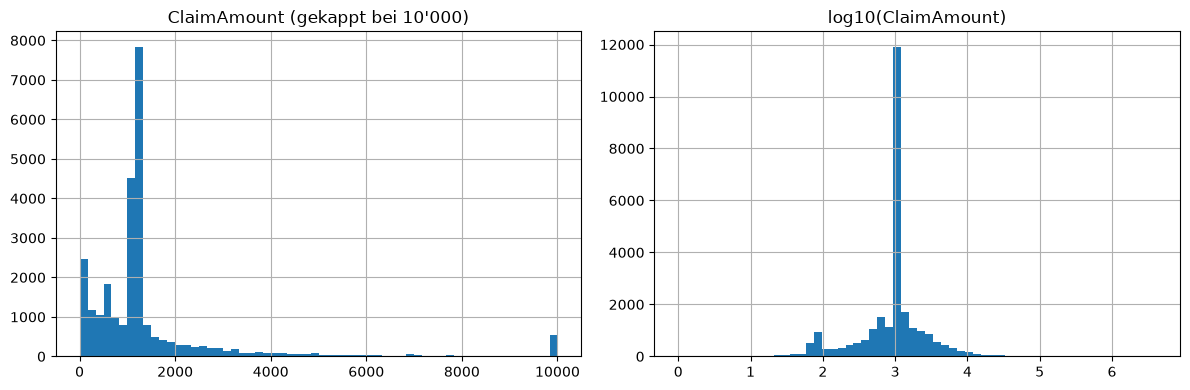

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sev["ClaimAmount"].clip(upper=10_000).hist(bins=60, ax=axes[0])
axes[0].set_title("ClaimAmount (gekappt bei 10'000)")

np.log10(sev["ClaimAmount"]).hist(bins=60, ax=axes[1])
axes[1].set_title("log10(ClaimAmount)")

plt.tight_layout()
plt.savefig("../results/03_severity_distribution.png", dpi=150)
plt.show()

In [17]:
# Wie stark dominieren Grossschäden?
q = sev["ClaimAmount"].quantile([0.5, 0.9, 0.99, 0.999])
print(q)
print("Anteil der Top-1%-Schäden am Gesamtschaden:",
      sev.nlargest(int(len(sev) * 0.01), "ClaimAmount")["ClaimAmount"].sum()
      / sev["ClaimAmount"].sum())

0.500      1172.00000
0.900      2799.07200
0.990     16793.70440
0.999    162784.44236
Name: ClaimAmount, dtype: float64
Anteil der Top-1%-Schäden am Gesamtschaden: 0.379283955846384


## Erkenntnisse aus der Exploration
- Datensatz: X Policen, Gesamtfrequenz Y %
- Exposure > 1 bei Z Policen -> wird in Phase 2 auf 1 gekappt
- Frequenz steigt mit BonusMalus deutlich
- Junge Fahrer (18-25) haben die höchste Frequenz
- Schadenhöhen stark rechtsschief, Top 1 % der Schäden machen N % des Gesamtschadens aus